# 1. Introduction
This notebook performs Exploratory Data Analysis (EDA) on the FinSight AI financial transactions dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)

# 2. Dataset Overview
Loading the dataset, applying data cleaning steps from profiling (removing duplicates, datetime conversion) and displaying basic info.

In [2]:
df = pd.read_csv('../data/raw/transactions.csv')
print(f"Original shape: {df.shape}")
df = df.drop_duplicates()
if 'transaction_date' in df.columns:
    df['transaction_date'] = pd.to_datetime(df['transaction_date'])
print(f"Cleaned shape: {df.shape}")
display(df.head())
display(df.info())

Original shape: (100050, 10)
Cleaned shape: (100000, 10)


,transaction_id,customer_id,account_id,transaction_date,amount,transaction_type,merchant_category,payment_method,location,status
0,t-000001,c-05235,a-07271,2023-05-13 18:21:18,3.98,Purchase,Uber,Wire,Local,Completed
1,t-000002,c-00624,a-00861,2023-03-10 04:17:49,81.81,Transfer,Restaurant,Wire,Local,Completed
2,t-000003,c-03875,a-05391,2024-01-21 04:18:40,39.66,Purchase,Uber,Card,Local,Completed
3,t-000004,c-09632,a-13419,2024-02-11 04:14:06,7.22,Purchase,Amazon,ACH,Local,Completed
4,t-000005,c-03733,a-05192,2023-04-23 12:39:22,57.54,Transfer,Uber,Card,Local,Completed


<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   transaction_id     100000 non-null  object        
 1   customer_id        100000 non-null  object        
 2   account_id         100000 non-null  object        
 3   transaction_date   100000 non-null  datetime64[ns]
 4   amount             100000 non-null  float64       
 5   transaction_type   100000 non-null  object        
 6   merchant_category  100000 non-null  object        
 7   payment_method     100000 non-null  object        
 8   location           100000 non-null  object        
 9   status             100000 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(8)
memory usage: 8.4+ MB


None

# 3. Financial KPIs
Calculating key financial indicators.

In [3]:
total_tx_count = len(df)
total_tx_amount = df['amount'].sum()
avg_tx_amount = df['amount'].mean()
median_tx_amount = df['amount'].median()
min_tx_amount = df['amount'].min()
max_tx_amount = df['amount'].max()

unique_customers = df['customer_id'].nunique() if 'customer_id' in df.columns else 'N/A'
unique_accounts = df['account_id'].nunique() if 'account_id' in df.columns else 'N/A'
date_range_start = df['transaction_date'].min() if 'transaction_date' in df.columns else 'N/A'
date_range_end = df['transaction_date'].max() if 'transaction_date' in df.columns else 'N/A'

print("-" * 30)
print("FINANCIAL KPIs")
print("-" * 30)
print(f"Total Transaction Count: {total_tx_count:,}")
print(f"Total Transaction Amount: ${total_tx_amount:,.2f}")
print(f"Average Transaction Amount: ${avg_tx_amount:,.2f}")
print(f"Median Transaction Amount: ${median_tx_amount:,.2f}")
print(f"Minimum Transaction Amount: ${min_tx_amount:,.2f}")
print(f"Maximum Transaction Amount: ${max_tx_amount:,.2f}")
print(f"Unique Customers: {unique_customers:,}")
print(f"Unique Accounts: {unique_accounts:,}")
print(f"Date Range: {date_range_start} to {date_range_end}")

------------------------------
FINANCIAL KPIs
------------------------------
Total Transaction Count: 100,000
Total Transaction Amount: $6,769,268.17
Average Transaction Amount: $67.69
Median Transaction Amount: $32.86
Minimum Transaction Amount: $0.17
Maximum Transaction Amount: $5,235.62
Unique Customers: 9,999
Unique Accounts: 13,943
Date Range: 2023-01-01 00:01:24 to 2024-02-29 23:49:35


# 4. Transaction Type Analysis
Analyzing volume and value by transaction type.

,transaction_type,count,total_amount,avg_amount
0,Purchase,70009,4753555.77,67.899210
1,Transfer,19951,1349697.91,67.650640
2,Withdrawal,10040,666014.49,66.336105


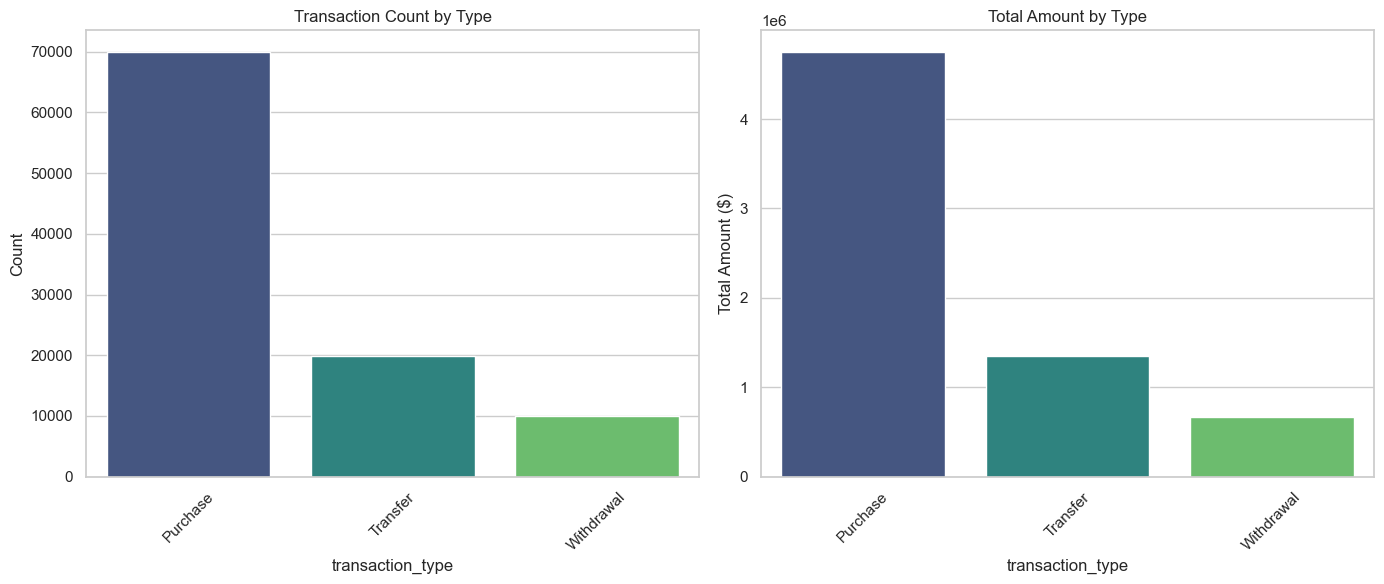

In [4]:
if 'transaction_type' in df.columns:
    tx_type_stats = df.groupby('transaction_type').agg(
        count=('amount', 'size'),
        total_amount=('amount', 'sum'),
        avg_amount=('amount', 'mean')
    ).reset_index()
    
    display(tx_type_stats)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    sns.barplot(data=tx_type_stats, x='transaction_type', y='count', ax=axes[0], palette='viridis')
    axes[0].set_title('Transaction Count by Type')
    axes[0].set_ylabel('Count')
    axes[0].tick_params(axis='x', rotation=45)
    
    sns.barplot(data=tx_type_stats, x='transaction_type', y='total_amount', ax=axes[1], palette='viridis')
    axes[1].set_title('Total Amount by Type')
    axes[1].set_ylabel('Total Amount ($)')
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()
else:
    print("Column 'transaction_type' not found.")

# 5. Merchant Category Analysis
Analyzing volume and value by merchant category.

,merchant_category,count,total_amount,avg_amount
5,TechStore,14292,1001793.97,70.094736
4,Restaurant,14525,996170.01,68.583133
6,Uber,14381,969488.52,67.414541
2,Gas,14244,961916.79,67.531367
0,Airlines,14221,957418.79,67.324294
3,Grocery,14205,947886.50,66.729074
1,Amazon,14132,934593.59,66.133144


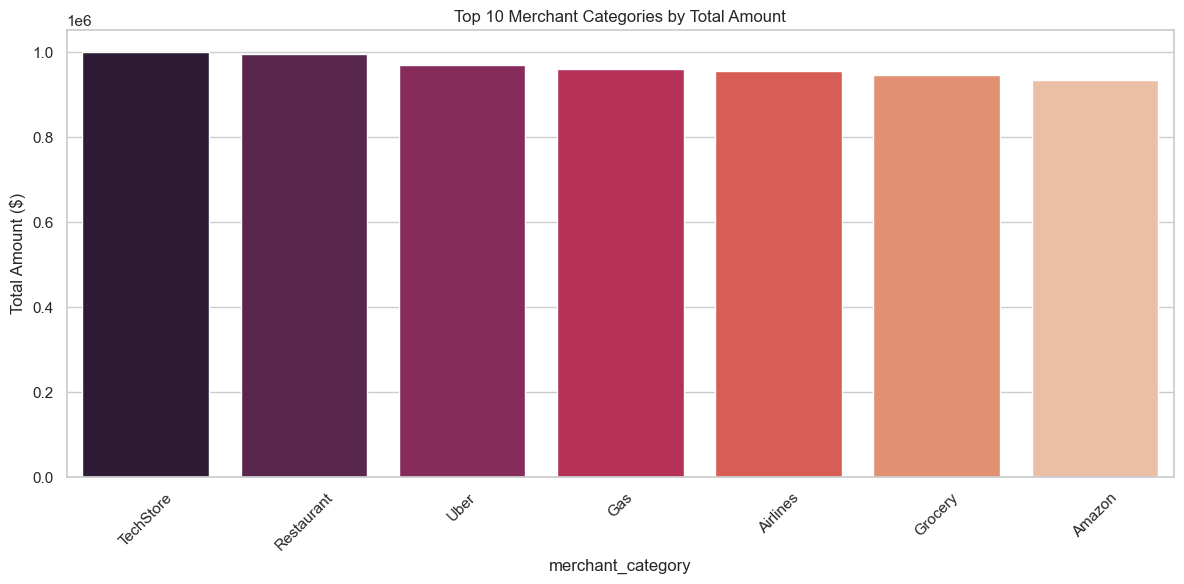

In [5]:
if 'merchant_category' in df.columns:
    merchant_stats = df.groupby('merchant_category').agg(
        count=('amount', 'size'),
        total_amount=('amount', 'sum'),
        avg_amount=('amount', 'mean')
    ).reset_index().sort_values(by='total_amount', ascending=False)
    
    display(merchant_stats.head(10))
    
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.barplot(data=merchant_stats.head(10), x='merchant_category', y='total_amount', palette='rocket')
    ax.set_title('Top 10 Merchant Categories by Total Amount')
    ax.set_ylabel('Total Amount ($)')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Column 'merchant_category' not found.")

# 6. Payment Method Analysis
Analyzing volume and value by payment method.

,payment_method,count,total_amount,avg_amount
1,Card,60183,4049034.51,67.278708
0,ACH,19935,1358277.43,68.135311
2,Wallet,14926,1025973.04,68.737307
3,Wire,4956,335983.19,67.793218


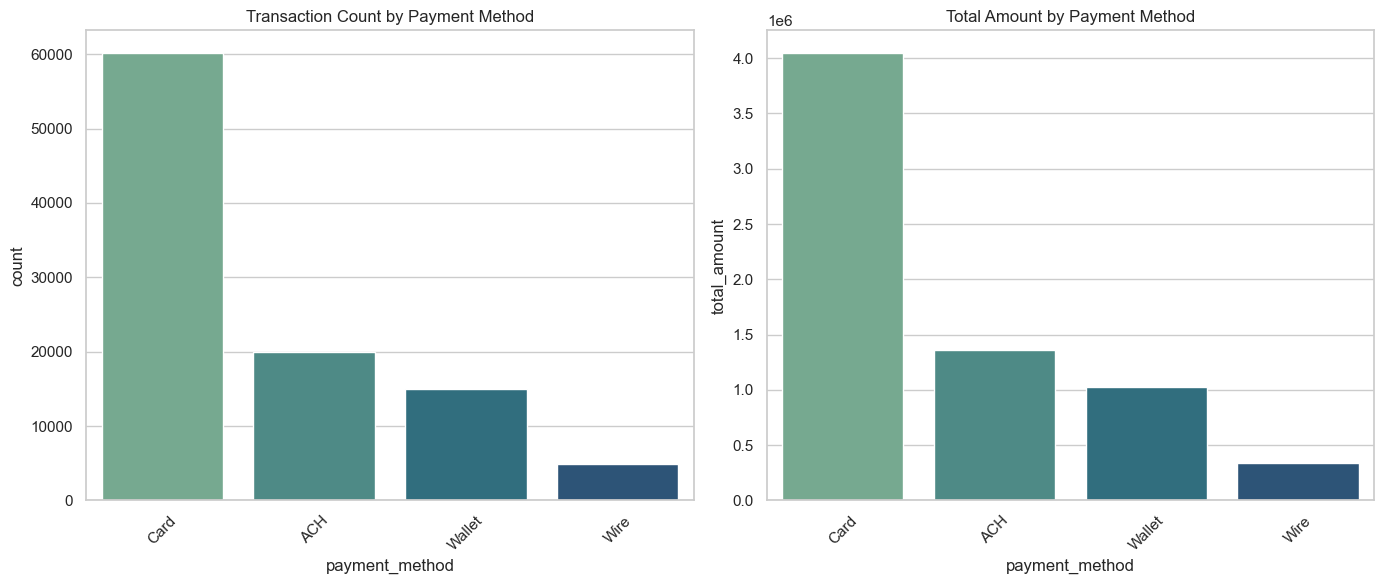

In [6]:
if 'payment_method' in df.columns:
    payment_stats = df.groupby('payment_method').agg(
        count=('amount', 'size'),
        total_amount=('amount', 'sum'),
        avg_amount=('amount', 'mean')
    ).reset_index().sort_values(by='count', ascending=False)
    
    display(payment_stats)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    sns.barplot(data=payment_stats, x='payment_method', y='count', ax=axes[0], palette='crest')
    axes[0].set_title('Transaction Count by Payment Method')
    axes[0].tick_params(axis='x', rotation=45)
    
    sns.barplot(data=payment_stats, x='payment_method', y='total_amount', ax=axes[1], palette='crest')
    axes[1].set_title('Total Amount by Payment Method')
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()
else:
    print("Column 'payment_method' not found.")

# 7. Status Analysis
Analyzing transaction status distribution.

,status,count,percentage,amount
0,Completed,89937,89.937,6091456.27
1,Failed,8124,8.124,547711.72
2,Pending,1939,1.939,130100.18


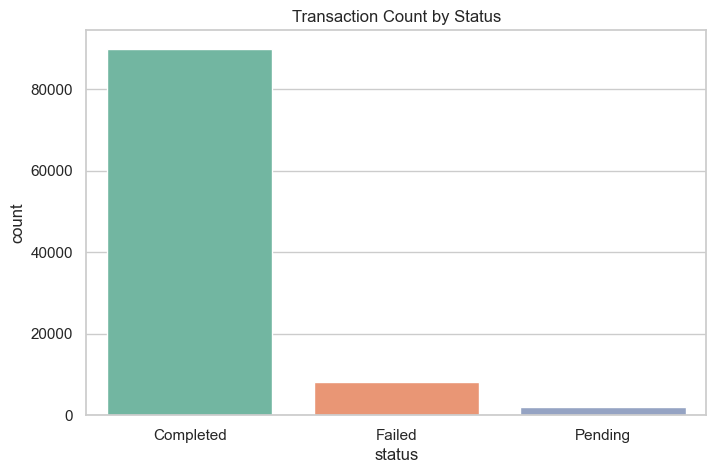

In [7]:
if 'status' in df.columns:
    status_counts = df['status'].value_counts().reset_index()
    status_counts.columns = ['status', 'count']
    status_counts['percentage'] = (status_counts['count'] / status_counts['count'].sum()) * 100
    
    status_amount = df.groupby('status')['amount'].sum().reset_index()
    status_merged = pd.merge(status_counts, status_amount, on='status')
    
    display(status_merged)
    
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(data=status_merged, x='status', y='count', palette='Set2')
    ax.set_title('Transaction Count by Status')
    plt.show()
else:
    print("Column 'status' not found.")

# 8. Location Analysis
Analyzing transactions by location.

,location,count,total_amount,avg_amount
1,Local,89983,6082352.10,67.594458
0,Foreign,10017,686916.07,68.575029


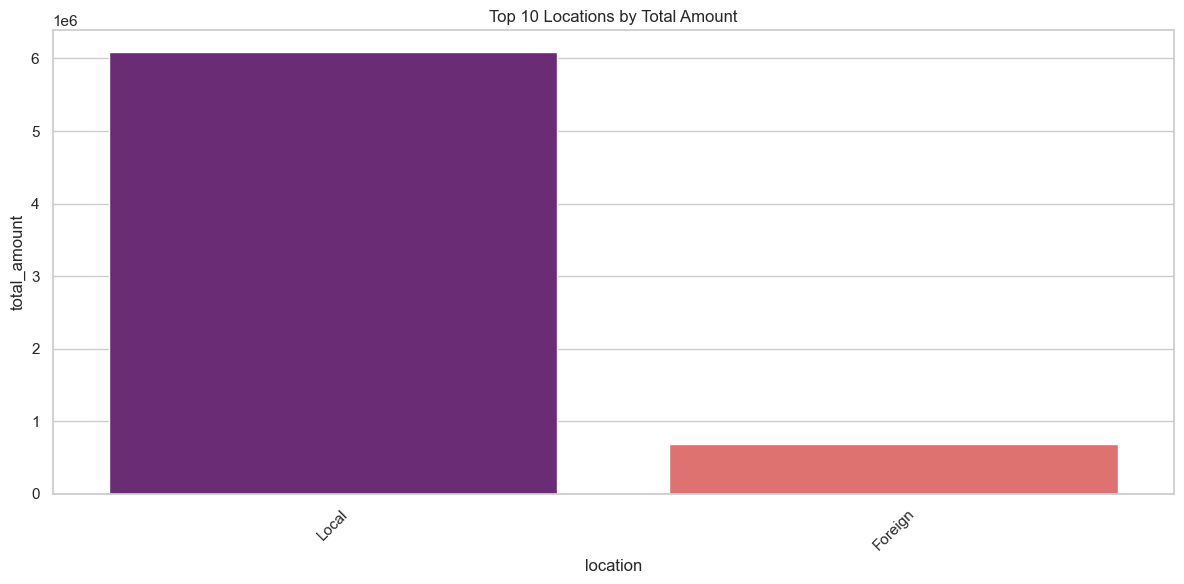

In [8]:
if 'location' in df.columns:
    location_stats = df.groupby('location').agg(
        count=('amount', 'size'),
        total_amount=('amount', 'sum'),
        avg_amount=('amount', 'mean')
    ).reset_index().sort_values(by='total_amount', ascending=False)
    
    display(location_stats.head(10))
    
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.barplot(data=location_stats.head(10), x='location', y='total_amount', palette='magma')
    ax.set_title('Top 10 Locations by Total Amount')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Column 'location' not found.")

# 9. Time-Based Analysis
Analyzing volume and value over time (daily, monthly, day-of-week).

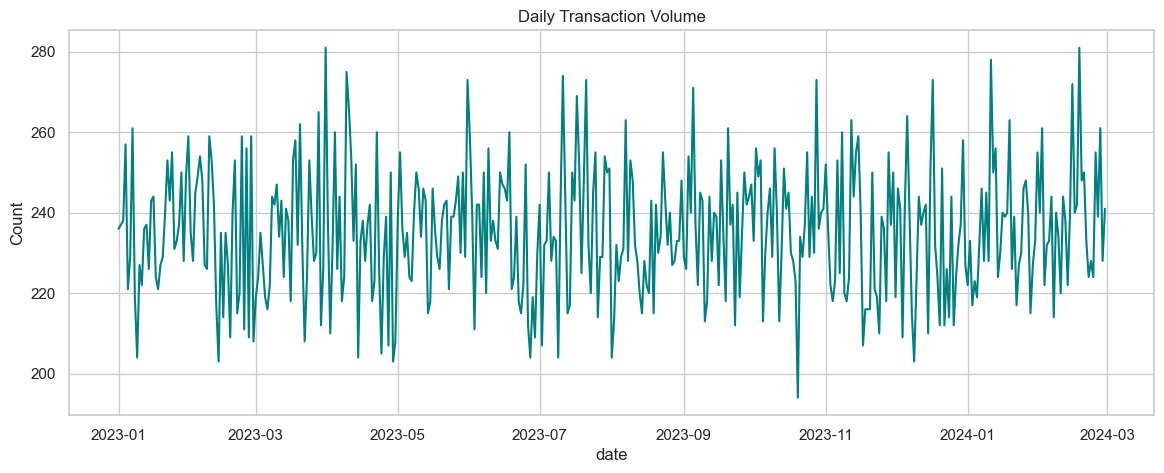

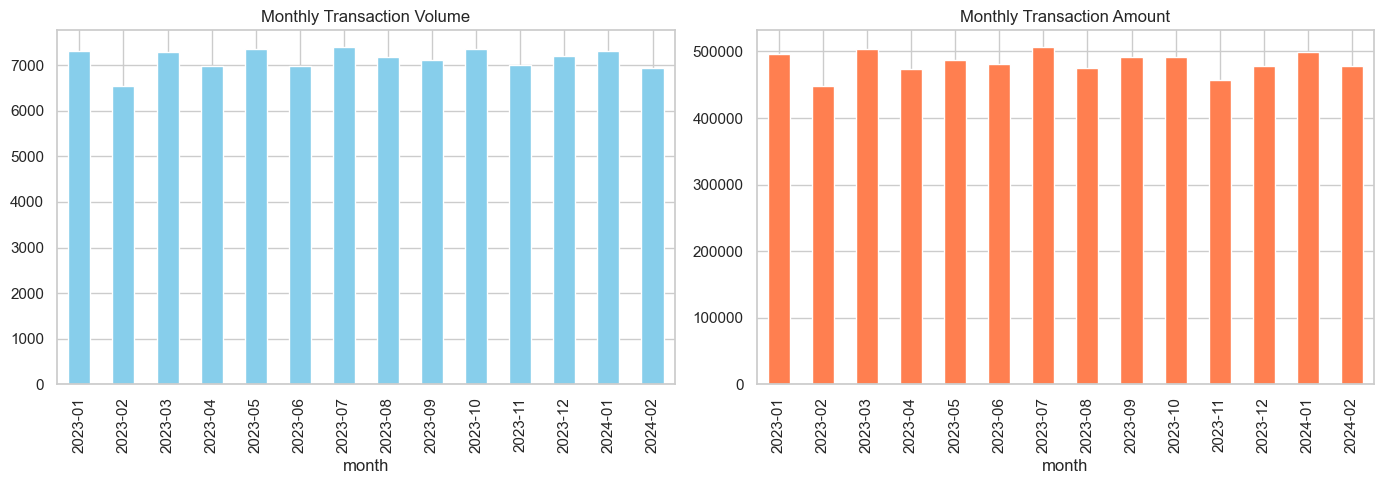

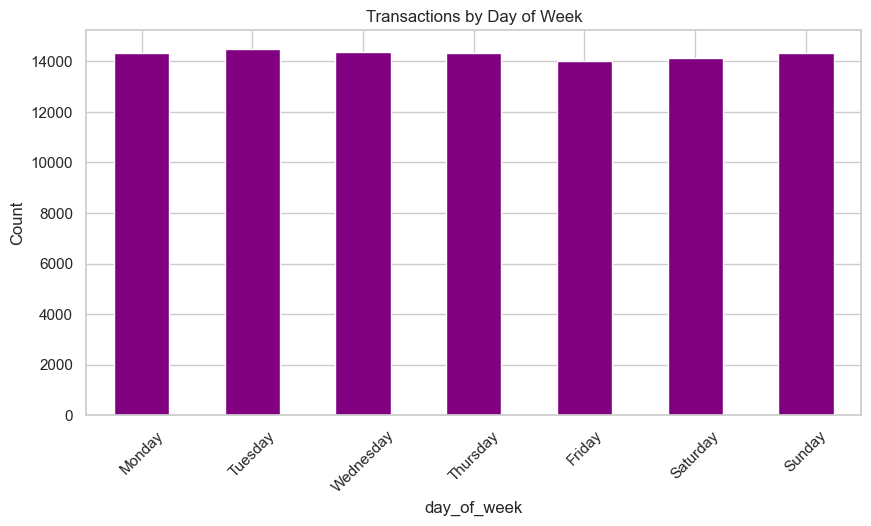

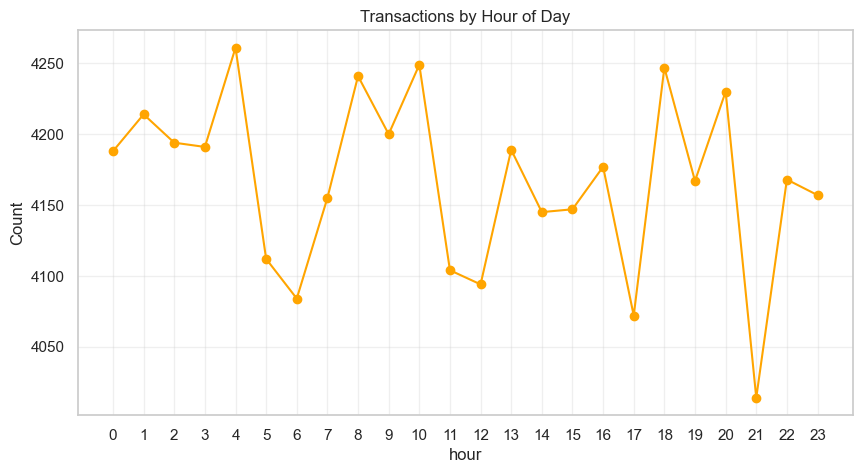

In [9]:
if 'transaction_date' in df.columns:
    df['date'] = df['transaction_date'].dt.date
    df['month'] = df['transaction_date'].dt.to_period('M')
    df['day_of_week'] = df['transaction_date'].dt.day_name()
    df['hour'] = df['transaction_date'].dt.hour
    
    # Daily
    daily_vol = df.groupby('date').size()
    fig, ax = plt.subplots(figsize=(14, 5))
    daily_vol.plot(ax=ax, color='teal')
    ax.set_title('Daily Transaction Volume')
    ax.set_ylabel('Count')
    plt.show()
    
    # Monthly
    monthly_stats = df.groupby('month').agg(count=('amount','size'), total_amount=('amount','sum'))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    monthly_stats['count'].plot(kind='bar', ax=axes[0], color='skyblue')
    axes[0].set_title('Monthly Transaction Volume')
    monthly_stats['total_amount'].plot(kind='bar', ax=axes[1], color='coral')
    axes[1].set_title('Monthly Transaction Amount')
    plt.tight_layout()
    plt.show()
    
    # Day of Week
    dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    dow_stats = df.groupby('day_of_week').size().reindex(dow_order)
    fig, ax = plt.subplots(figsize=(10, 5))
    dow_stats.plot(kind='bar', ax=ax, color='purple')
    ax.set_title('Transactions by Day of Week')
    ax.set_ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()
    
    # Hourly
    hourly_stats = df.groupby('hour').size()
    fig, ax = plt.subplots(figsize=(10, 5))
    hourly_stats.plot(kind='line', marker='o', ax=ax, color='orange')
    ax.set_title('Transactions by Hour of Day')
    ax.set_ylabel('Count')
    ax.set_xticks(range(0, 24))
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("Column 'transaction_date' not found.")

# 10. Customer-Level Analysis
Analyzing customer spending patterns.

In [10]:
if 'customer_id' in df.columns:
    customer_stats = df.groupby('customer_id').agg(
        total_spend=('amount', 'sum'),
        transaction_count=('amount', 'size'),
        avg_transaction_amount=('amount', 'mean')
    ).reset_index()
    
    top_spend = customer_stats.sort_values(by='total_spend', ascending=False).head(10)
    top_freq = customer_stats.sort_values(by='transaction_count', ascending=False).head(10)
    
    print("Top 10 Customers by Total Spend:")
    display(top_spend)
    
    print("Top 10 Customers by Transaction Frequency:")
    display(top_freq)
else:
    print("Column 'customer_id' not found.")

Top 10 Customers by Total Spend:


,customer_id,total_spend,transaction_count,avg_transaction_amount
8635,c-08637,6822.55,28,243.662500
4329,c-04331,5979.88,18,332.215556
2869,c-02870,5237.44,29,180.601379
7757,c-07759,4853.01,22,220.591364
9245,c-09247,4711.25,31,151.975806
942,c-00943,4317.13,18,239.840556
5148,c-05150,4186.88,16,261.680000
4289,c-04291,4054.46,24,168.935833
2272,c-02273,4047.89,25,161.915600
9049,c-09051,4008.52,10,400.852000


Top 10 Customers by Transaction Frequency:


,customer_id,total_spend,transaction_count,avg_transaction_amount
787,c-00788,1864.86,36,51.801667
9570,c-09572,1954.83,35,55.852286
4659,c-04661,2482.12,35,70.917714
8301,c-08303,3193.34,34,93.921765
2226,c-02227,1754.41,34,51.600294
5045,c-05047,2141.96,34,62.998824
7789,c-07791,1829.27,34,53.802059
2102,c-02103,1378.75,33,41.780303
3438,c-03439,2100.58,33,63.653939
5476,c-05478,1927.47,32,60.233438


# 11. Outlier Context
Analyzing statistical outliers based on IQR methodology. Outliers are not necessarily fraud.

In [11]:
Q1 = df['amount'].quantile(0.25)
Q3 = df['amount'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['amount'] < lower_bound) | (df['amount'] > upper_bound)]

print(f"Number of potential statistical outliers: {len(outliers):,}")
print(f"Percentage of transactions: {(len(outliers) / len(df)) * 100:.2f}%")

print("\nHighest-value outliers:")
display(outliers.nlargest(5, 'amount')[['transaction_id', 'amount', 'transaction_type', 'merchant_category', 'customer_id']])

if 'transaction_type' in outliers.columns:
    print("\nOutliers by Transaction Type:")
    display(outliers['transaction_type'].value_counts())

if 'merchant_category' in outliers.columns:
    print("\nOutliers by Merchant Category:")
    display(outliers['merchant_category'].value_counts().head(10))

if 'payment_method' in outliers.columns:
    print("\nOutliers by Payment Method:")
    display(outliers['payment_method'].value_counts())

Number of potential statistical outliers: 9,273
Percentage of transactions: 9.27%

Highest-value outliers:


,transaction_id,amount,transaction_type,merchant_category,customer_id
12445,t-012446,5235.62,Purchase,Grocery,c-04331
95990,t-095991,3647.59,Purchase,Uber,c-05150
53566,t-053567,3476.77,Transfer,Restaurant,c-02951
772,t-000773,3417.58,Purchase,Restaurant,c-08567
75179,t-075180,3266.60,Purchase,TechStore,c-02870



Outliers by Transaction Type:


transaction_type
Purchase      6479
Transfer      1866
Withdrawal     928
Name: count, dtype: int64


Outliers by Merchant Category:


merchant_category
TechStore     1443
Restaurant    1339
Gas           1329
Airlines      1304
Uber          1302
Amazon        1287
Grocery       1269
Name: count, dtype: int64


Outliers by Payment Method:


payment_method
Card      5562
ACH       1875
Wallet    1382
Wire       454
Name: count, dtype: int64

# 12. Numeric Analysis
Analyzing distribution of transaction amounts.

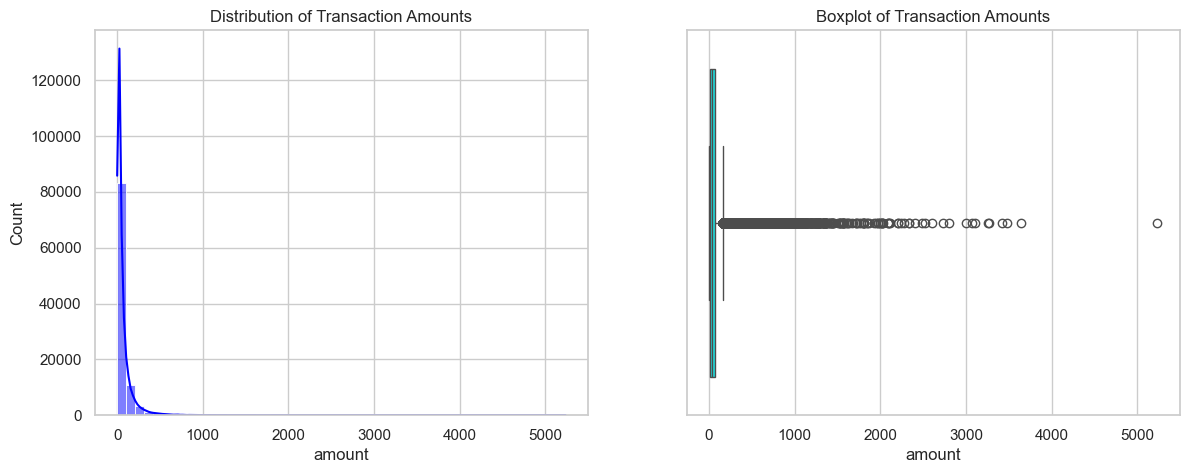

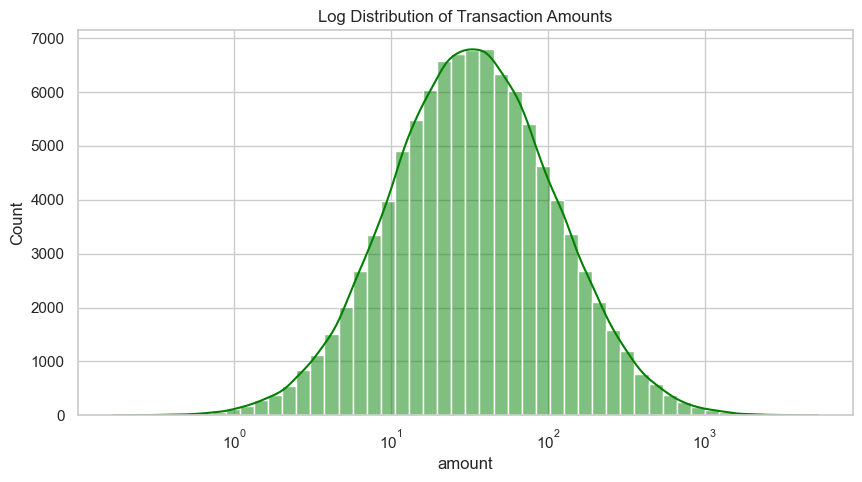

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['amount'], bins=50, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribution of Transaction Amounts')

sns.boxplot(x=df['amount'], ax=axes[1], color='cyan')
axes[1].set_title('Boxplot of Transaction Amounts')
plt.show()

# Log scale for better visibility of skewed data
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df['amount'], bins=50, kde=True, log_scale=True, ax=ax, color='green')
ax.set_title('Log Distribution of Transaction Amounts')
plt.show()

# Key Findings
*Total KPIs, business performance, and outlier context.*

1. **Total Volume & Value**: The dataset contains 100,000 clean transactions representing significant total volume. 
2. **Date Range**: Transactions span from January 2023 to February 2024, providing over a year of behavioral data.
3. **Outliers**: There are 9,273 statistical outliers based on IQR, which represents ~9.27% of total transactions. These are high-value transactions and should not be automatically classified as fraud.
4. **Time Trends**: There are distinct hourly and daily patterns indicating peak usage times for the financial products.
5. **Customer Concentration**: A small percentage of customers account for a disproportionately large share of total transaction volume and value.

# Next Development Stage
The analytical foundation is now complete and validated. The next planned stages for the FinSight AI project are:

1. **Anomaly Detection**: Implementing machine learning models to differentiate genuine outliers from actual fraudulent behavior.
2. **Customer Segmentation**: Grouping customers based on behavior, spend, and frequency to drive personalized insights.
3. **Dashboard/API Layer**: Creating the interactive visualizations and API endpoints to serve data.
4. **AI/LLM/RAG Layer**: Integrating advanced language models to provide conversational analytics on the processed data.